In [ ]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
train_df = pd.read_csv('train.csv')
test_df = pd.read_csv('test.csv')

Y_train = train_df['SalePrice'].to_numpy(dtype=np.float32)
X_train_df = train_df.drop(columns=['Id', 'SalePrice'])
X_test_df = test_df.drop(columns=['Id'])

X_train_df = pd.get_dummies(X_train_df)
X_test_df = pd.get_dummies(X_test_df)

X_train_df, X_test_df = X_train_df.align(X_test_df, join='left', axis=1, fill_value=0)

X_train = X_train_df.to_numpy(dtype=np.float32)
X_test = X_test_df.to_numpy(dtype=np.float32)

In [3]:
from sklearn.preprocessing import StandardScaler

X_train = np.nan_to_num(X_train, nan=0.0, posinf=0.0, neginf=0.0)
X_test = np.nan_to_num(X_test, nan=0.0, posinf=0.0, neginf=0.0)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train = np.hstack([np.ones((X_train.shape[0], 1)), X_train])
X_test = np.hstack([np.ones((X_test.shape[0], 1)), X_test])

In [4]:
Y_train = np.log1p(Y_train)

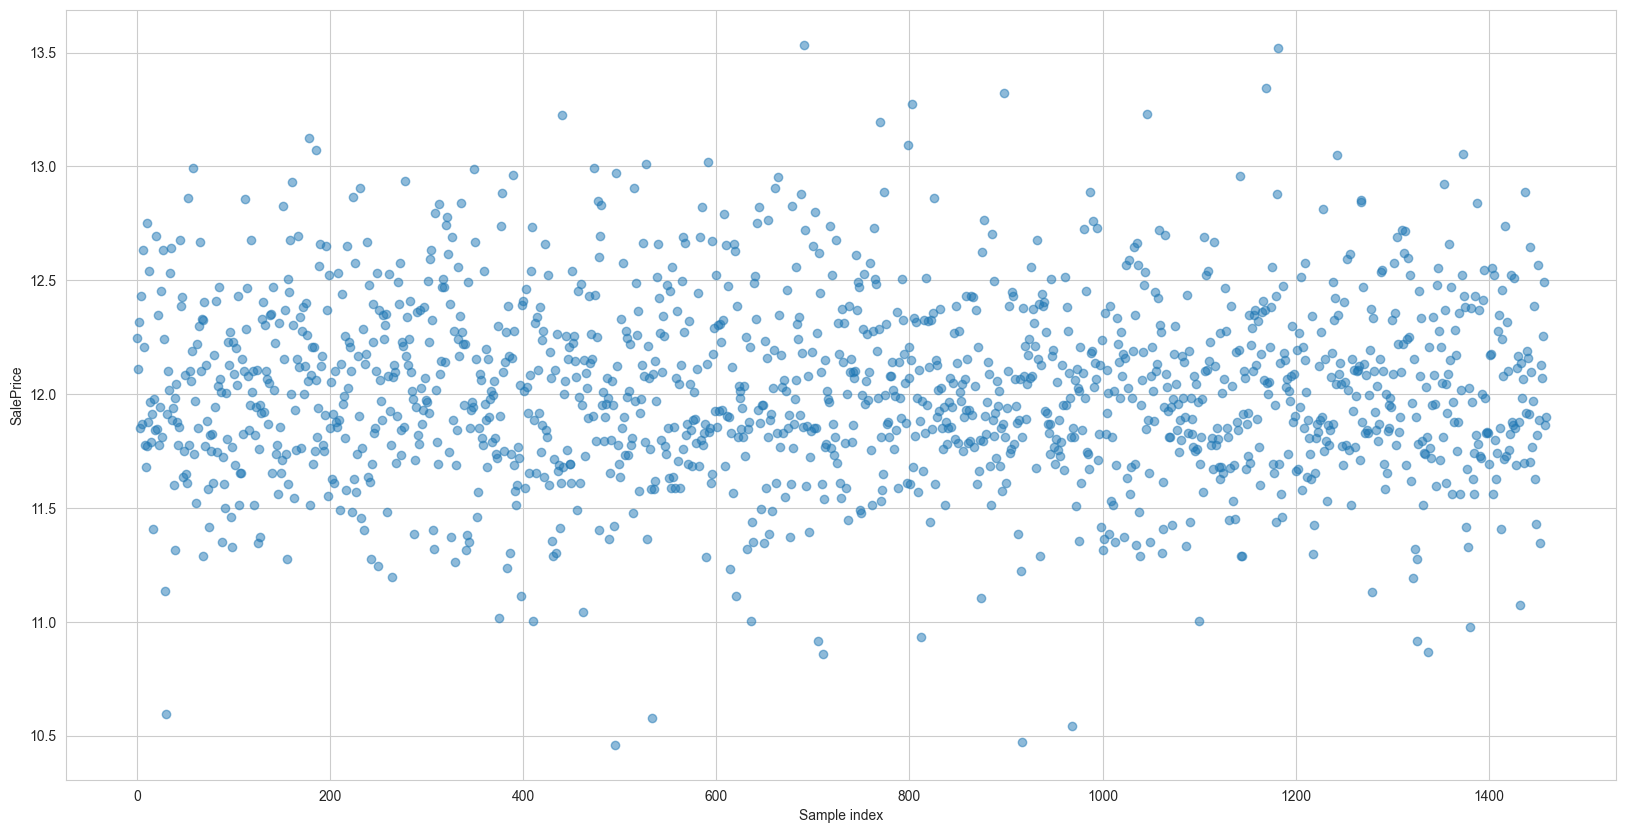

In [5]:
plt.figure(figsize=(20,10))
plt.scatter(range(len(Y_train)), Y_train, alpha=0.5)
plt.xlabel("Sample index")
plt.ylabel("SalePrice")
plt.show()

In [9]:
random_seed = 42
num_steps = 1000000
n_objects = Y_train.shape[0]
w_0 = np.random.uniform(-1e-2, 1e-2, X_train.shape[1])

In [10]:
np.random.seed(random_seed)
batch_size = 1000
w = w_0.copy()
w_history_list = [w.copy()]
lr = 1e-3
eps = 1e-3
loss_history = []

for i in range(num_steps):
    sample_indices = np.random.randint(low=0, high=n_objects, size=batch_size)
    X_batch = X_train[sample_indices, :]
    Y_batch = Y_train[sample_indices]
    grad = 2. * np.dot(X_batch.T, X_batch @ w - Y_batch) / batch_size + eps * w
    w -= lr * grad

    train_pred = X_train @ w
    loss = np.mean((train_pred - Y_train)**2)
    loss_history.append(loss)

    if(i % 1000 == 0):
        print(loss)

143.97317433373019
2.647776572720561
0.06007907419667013
0.010666029690488674
0.009350837135098143
0.009215568331358344
0.00916421013652482
0.009131488726930847
0.009107268474906298
0.00909167004136255
0.009079234840784961
0.009069048985200225
0.009063286596782558
0.009058026794707129
0.009053675663536329
0.009048200565858675
0.009044643290195454
0.009043049997233408
0.009040198130604658
0.009039984978178824
0.009034039594136347
0.00903682800568174
0.0090331758800291
0.009034686623109871
0.009031660284422286
0.009032725157406427
0.00903027977324325
0.009029616489401752
0.009028515602447261
0.009026888040750783
0.009028324780936604
0.009025521847053354
0.009026111966341082
0.009024974878883462
0.009027231492881963
0.009028754615887268
0.00902741976066391
0.009028408770066505
0.009025299958056721
0.009022893982757244
0.009024762196180588
0.009022699700554426
0.009022810790507207
0.00902539157467762
0.009024572414991949
0.009022380305724893
0.009023376615467907
0.009021758262290158
0.0090

In [11]:
Y_pred = np.expm1(X_train @ w)

for i in range(len(X_train)):
    print(f"Predicted = {Y_pred[i]}, Label = {np.expm1(Y_train[i])}")

Predicted = 205345.7194917215, Label = 208499.9375
Predicted = 200212.366202348, Label = 181500.0
Predicted = 213122.64012006397, Label = 223499.984375
Predicted = 165473.39504012422, Label = 140000.0625
Predicted = 285746.56692400575, Label = 250000.0
Predicted = 140950.13606831493, Label = 143000.0625
Predicted = 276502.2878051961, Label = 307000.03125
Predicted = 220920.39739491395, Label = 199999.984375
Predicted = 124222.14077592289, Label = 129899.953125
Predicted = 120927.81366620012, Label = 118000.0390625
Predicted = 129515.65835238763, Label = 129500.0546875
Predicted = 376205.90910992, Label = 345000.03125
Predicted = 131557.8469753113, Label = 144000.046875
Predicted = 221003.555721308, Label = 279499.96875
Predicted = 145874.62325738114, Label = 156999.984375
Predicted = 137718.05556952467, Label = 131999.96875
Predicted = 156831.96777366046, Label = 148999.9375
Predicted = 107538.34579840188, Label = 89999.9609375
Predicted = 148322.077988671, Label = 158999.953125
Predic

In [12]:
Y_pred = np.expm1(X_test @ w)

submission = pd.DataFrame({
    "Id": test_df["Id"],
    "SalePrice": Y_pred
})

submission.to_csv("submission.csv", index=False)